# IMDB Movies Dataset — Complete Analysis & Visualisation
Educational notebook with clean pandas and matplotlib/seaborn examples.

## Q1. How do we load the dataset and see the first 5 rows?

In [ ]:

import pandas as pd

# read_csv loads the dataset into a pandas DataFrame
df = pd.read_csv("movies.csv")

# head() returns the first N rows (default = 5)
df.head()


,id,name,year,rating,certificate,duration,genre,votes,gross_income,directors_id,directors_name,stars_id,stars_name,description
0,tt0068646,The Godfather,1972,9.2,R,175 min,"Crime, Drama",1798749,"134,966,411",nm0000338,Francis Ford Coppola,"nm0000008,nm0000199,nm0001001,nm0000473","Marlon Brando,Al Pacino,James Caan,Diane Keaton",The aging patriarch of an organized crime dyna...
1,tt5113044,Minions: The Rise of Gru,2022,7.3,PG,87 min,"Animation, Adventure, Comedy","1,220","134,966,411","nm0049633,nm1556070,nm3646390","Kyle Balda,Brad Ableson,Jonathan del Val","nm0136797,nm1853544,nm0000273,nm0378245","Steve Carell,Pierre Coffin,Alan Arkin,Taraji P...",The untold story of one twelve-year-old's drea...
2,tt7657566,Death on the Nile,2022,6.3,PG-13,127 min,"Crime, Drama, Mystery","121,063","134,966,411",nm0000110,Kenneth Branagh,"nm5290643,nm0000906,nm0000110,nm1258970","Tom Bateman,Annette Bening,Kenneth Branagh,Rus...","While on vacation on the Nile, Hercule Poirot ..."
3,tt8115900,The Bad Guys,2022,6.9,PG,100 min,"Animation, Adventure, Comedy","23,090","134,966,411",nm2010048,Pierre Perifel,"nm0005377,nm0549505,nm5377144,nm0732497","Sam Rockwell,Marc Maron,Awkwafina,Craig Robinson",Several reformed yet misunderstood criminal an...
4,tt10809742,Collision,2022,3.8,TV-MA,99 min,"Crime, Drama, Thriller",656,"134,966,411",nm1926494,Fabien Martorell,"nm1339181,nm0456810,nm12651040,nm7357127","Tessa Jubber,Langley Kirkwood,Zoey Sneedon,Bon...",Freedom always comes at a price.


## Q2. What are the data types of each column?

In [ ]:

# info() prints column names, non‑null counts and data types
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 19808 entries, 0 to 19807
Data columns (total 14 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   id              19808 non-null  object 
 1   name            19808 non-null  object 
 2   year            19808 non-null  int64  
 3   rating          19808 non-null  float64
 4   certificate     19808 non-null  object 
 5   duration        19808 non-null  object 
 6   genre           19808 non-null  object 
 7   votes           19808 non-null  object 
 8   gross_income    19808 non-null  object 
 9   directors_id    19808 non-null  object 
 10  directors_name  19808 non-null  object 
 11  stars_id        19808 non-null  object 
 12  stars_name      19808 non-null  object 
 13  description     19808 non-null  object 
dtypes: float64(1), int64(1), object(12)
memory usage: 2.1+ MB


## Q3. Clean the duration column ('175 min' → 175)

In [ ]:

# remove text 'min'
df["duration"] = df["duration"].str.replace("min","", regex=False)

# remove commas if present
df["duration"] = df["duration"].str.replace(",","", regex=False)

# convert to integer
df["duration"] = df["duration"].astype(int)

df["duration"].head()


,duration
0,175
1,87
2,127
3,100
4,99


## Q4. Clean the gross and votes columns

In [ ]:

# remove commas from numbers
df["gross_income"] = df["gross_income"].str.replace(",", "", regex=False)
df["votes"] = df["votes"].str.replace(",", "", regex=False)

# convert to numeric
df["gross_income"] = pd.to_numeric(df["gross_income"], errors="coerce")
df["votes"] = pd.to_numeric(df["votes"], errors="coerce")

df[["gross_income","votes"]].head()


,gross_income,votes
0,134966411.0,1798749
1,134966411.0,1220
2,134966411.0,121063
3,134966411.0,23090
4,134966411.0,656


## Q5. Missing values in each column

In [ ]:

# isnull() detects missing values
# sum() counts them column‑wise
df.isnull().sum()


,0
id,0
name,0
year,0
rating,0
certificate,0
duration,0
genre,0
votes,0
gross_income,19
directors_id,0


## Q6. Handle missing ratings

In [ ]:

# simple strategy: replace missing ratings with the median rating
median_rating = df["rating"].median()

df["rating"] = df["rating"].fillna(median_rating)

df["rating"].isnull().sum()


np.int64(0)

## Q7. Hidden Gems (High Rating, Low Votes)

In [ ]:

hidden_gems = df[(df["rating"] > 8) & (df["votes"] < 20000)]

hidden_gems[["name","rating","votes"]].sort_values("rating", ascending=False).head()


,name,rating,votes
10866,My Butt Hazza Fever,9.7,14
17609,Bullet Proof,9.6,61
17050,Seven Lost,9.2,38
9242,Ramayana: The Legend of Prince Rama,9.1,4756
16016,Totally Connected,9.0,65


## Q8. Overhyped Movies (Low Rating, High Gross)

In [ ]:

overhyped = df[(df["rating"] < 6) & (df["gross_income"] > df["gross_income"].quantile(0.75))]

overhyped[["name","rating","gross_income"]].sort_values("gross_income", ascending=False).head()


,name,rating,gross_income
17321,Memory,5.6,515202542.0
10479,Tom and Jerry,5.2,486295561.0
9090,CATS貓,2.8,477373578.0
13202,Transformers: Revenge of the Fallen,5.9,402111870.0
9076,灰姑娘,4.2,400738009.0


## Q9. Unique Certificates

In [ ]:

df["certificate"].unique()


array(['R', 'PG', 'PG-13', 'TV-MA', 'Not Rated', 'Approved', 'TV-14',
       'NC-17', 'Unrated', 'G', 'Passed', 'GP', 'X', 'M/PG', 'M', 'TV-PG',
       'TV-G', '12', 'TV-13', 'TV-Y7-FV', 'MA-17', 'AO', '18', 'R-15',
       'R-12', 'R-18', 'PG-12', '6+', 'TV-Y7', 'TV-Y', 'MA-13'],
      dtype=object)

## Q10. Movies released per year

In [ ]:

movies_per_year = df["year"].value_counts().sort_index()
movies_per_year.head()


,count
year,
1894,1
1898,1
1902,2
1903,1
1913,3


## Q11. Top 5 most common genres

In [ ]:

# genre column usually contains multiple genres separated by comma
genres = df["genre"].str.split(",", expand=True).stack()

top_genres = genres.value_counts().head(5)

top_genres


,count
Drama,6579
Action,4989
Thriller,3928
Drama,3076
Crime,2889


## Q12. Directors with most movies

In [ ]:

df["directors_name"].value_counts().head(10)


,count
directors_name,
Alfred Hitchcock,38
Clint Eastwood,36
Henry Hathaway,29
Steven Spielberg,29
Raoul Walsh,27
John Ford,26
Jesús Franco,26
John Huston,25
Ridley Scott,25


## Q13. Do longer movies get better ratings?

In [ ]:

df[["duration","rating"]].corr()


,duration,rating
duration,1.000000,0.130112
rating,0.130112,1.000000


## Q14. Genre with highest average rating

In [ ]:

genres = df.assign(genre=df["genre"].str.split(",")).explode("genre")

genres.groupby("genre")["rating"].mean().sort_values(ascending=False).head()


,rating
genre,
Documentary,7.187100
Short,7.117143
Reality-TV,7.100000
Biography,7.090317
Short,6.997674


## Q15. Genre that makes the most money

In [ ]:

genres.groupby("genre")["gross_income"].mean().sort_values(ascending=False).head()


,gross_income
genre,
Adventure,5.510941e+07
Animation,4.635788e+07
Sci-Fi,3.469687e+07
Comedy,3.198515e+07
Fantasy,2.979168e+07


## Q16. Highest grossing director

In [ ]:

df.groupby("directors_name")["gross_income"].sum().sort_values(ascending=False).head()


,gross_income
directors_name,
Steven Spielberg,4.247700e+09
Michael Bay,2.703051e+09
"Anthony Russo,Joe Russo",2.262877e+09
J.J. Abrams,2.199407e+09
Peter Jackson,2.156934e+09


## Q17. How certificate affects gross income

In [ ]:

df.groupby("certificate")["gross_income"].mean().sort_values(ascending=False)


,gross_income
certificate,
GP,6.221153e+07
PG-13,4.573364e+07
MA-17,3.806747e+07
R-18,3.474929e+07
PG,3.000706e+07
G,2.575243e+07
R-12,2.033680e+07
PG-12,1.744778e+07
R,1.420369e+07


## Q18. Average duration by certificate

In [ ]:

df.groupby("certificate")["duration"].mean().sort_values(ascending=False)


,duration
certificate,
R-15,127.333333
R-18,126.571429
R-12,123.339623
PG-12,117.540984
6+,114.000000
M/PG,110.666667
PG-13,106.786859
M,105.793103
Not Rated,104.813337


## Q19. Are ratings improving over time?

In [ ]:

df.groupby("year")["rating"].mean().tail()


,rating
year,
2018,5.935598
2019,5.914460
2020,5.577516
2021,5.741064
2022,5.481609


## Q20. Actor appearing in most movies

In [ ]:

a = df["stars_name"].str.split(",").explode("star_name")

a.value_counts().head(5)


,count
stars_name,
Nicolas Cage,76
Samuel L. Jackson,72
Bruce Willis,71
John Wayne,71
Robert De Niro,62


## Q21. Correlation between votes and gross

In [ ]:

df[["votes","gross_income"]].corr()


,votes,gross_income
votes,1.000000,0.632642
gross_income,0.632642,1.000000


## Q22. Most frequent Director + Actor duo

In [ ]:

duo = df.groupby(["directors_name","stars_name"]).size().sort_values(ascending=False)

duo.head()


,,0
directors_name,stars_name,
"Lana Wachowski,Lilly Wachowski","Keanu Reeves,Laurence Fishburne,Carrie-Anne Moss,Hugo Weaving",3
John Waters,"Divine,David Lochary,Mary Vivian Pearce,Mink Stole",3
"Yukihiro Miyamoto,Akiyuki Shinbo","Aoi Yûki,Chiwa Saitô,Eri Kitamura,Kaori Mizuhashi",3
Mike Gunther,"Will Yun Lee,Jermaine Love,Rory Markham,Bertrand-Xavier Corbi",3
Sylvester Stallone,"Sylvester Stallone,Talia Shire,Burt Young,Carl Weathers",3


## Q23. Year with highest total industry revenue

In [ ]:

df.groupby("year")["gross_income"].sum().sort_values(ascending=False).head()


,gross_income
year,
2021,2.045426e+10
2019,1.731288e+10
2018,1.470025e+10
2017,1.307425e+10
2016,1.244255e+10


## Q24. Best genre for debut directors

In [ ]:

first_movies = df.sort_values("year").groupby("directors_name").first()

first_movies.assign(
    genre=first_movies["genre"].str.split(",")
).explode("genre").groupby("genre")["rating"].mean().sort_values(ascending=False).head()


,rating
genre,
Documentary,7.186410
Biography,7.117473
Short,7.116049
Reality-TV,7.100000
Short,6.950769


## Q25. Do ensemble casts earn more?

In [ ]:

# count number of actors listed
df["actor_count"] = df["stars_name"].str.split(",")

# Count number of actors per movie
df["actor_count"] = df["actor_count"].apply(len)

df.groupby("actor_count")["gross_income"].mean()


,gross_income
actor_count,
1,2.192272e+06
2,2.522776e+06
3,2.332324e+06
4,1.697779e+07


## Q26. Director with highest hit rate (rating > 7.5)

In [ ]:

df["hit"] = df["rating"] > 7.5

hit_rate = df.groupby("directors_name")["hit"].mean().sort_values(ascending=False)

hit_rate.head()


,hit
directors_name,
Vijaya Baapineedu,1.0
Hannes Rossacher,1.0
S.R. Bindler,1.0
S.J. Suryah,1.0
H. Vinoth,1.0


## Q27. Sequel Effect (numbers in movie titles)

In [ ]:

df["is_sequel"] = df["name"].str.contains(r"\d")

df.groupby("is_sequel")["gross_income"].mean()


,gross_income
is_sequel,
False,1.617510e+07
True,2.984256e+07


## Q28. Business Decision — What movie should we fund?

In [ ]:

# heuristic strategy:
# choose genre with high rating and strong gross performance

genre_rating = genres.groupby("genre")["rating"].mean()
genre_gross = genres.groupby("genre")["gross_income"].mean()

strategy = pd.concat([genre_rating, genre_gross], axis=1)
strategy.columns = ["avg_rating","avg_gross"]

strategy.sort_values(["avg_rating","avg_gross"], ascending=False).head()


,avg_rating,avg_gross
genre,,
Documentary,7.187100,2.948114e+06
Short,7.117143,5.691006e+06
Reality-TV,7.100000,1.691439e+06
Biography,7.090317,5.496417e+06
Short,6.997674,5.311999e+06


# Visualisation Section

In [ ]:

import matplotlib.pyplot as plt
import seaborn as sns


### Q1. Average rating over years

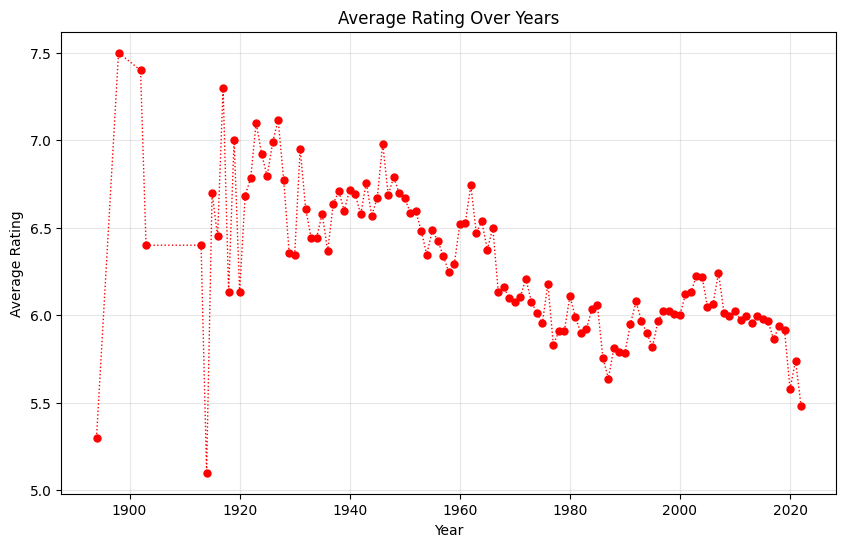

In [ ]:

avg_rating_year = df.groupby("year")["rating"].mean()

plt.figure(figsize=(10,6))
plt.plot(avg_rating_year.index, avg_rating_year.values, marker="o", color="red",linestyle="dotted", markersize=5, linewidth=1)
plt.xlabel("Year")
plt.ylabel("Average Rating")
plt.title("Average Rating Over Years")
plt.grid(alpha= 0.3)
plt.show()


### Q2. Number of movies per year

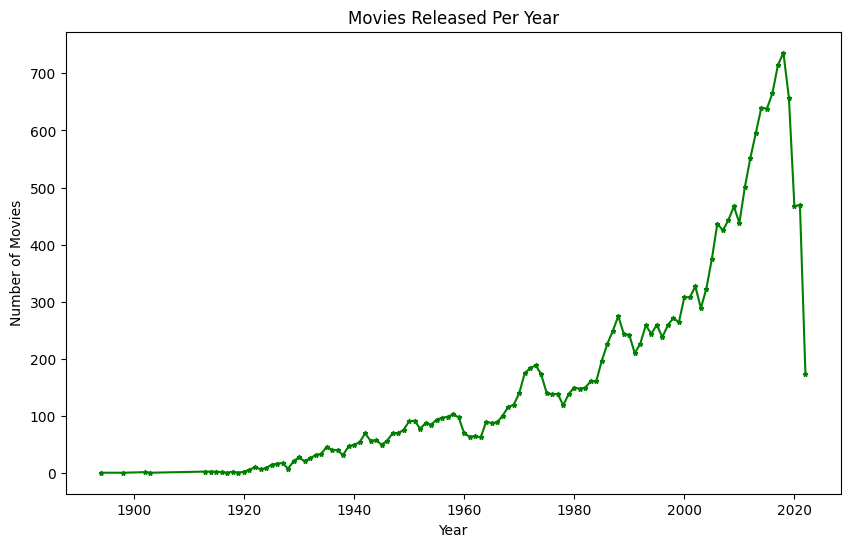

In [ ]:

movies_per_year = df["year"].value_counts().sort_index()

plt.figure(figsize=(10,6))
plt.plot(movies_per_year.index, movies_per_year.values, marker="*", markersize=3.5, color="green")

plt.xlabel("Year")
plt.ylabel("Number of Movies")
plt.title("Movies Released Per Year")
plt.show()


### Q3. Rating distribution (Matplotlib)

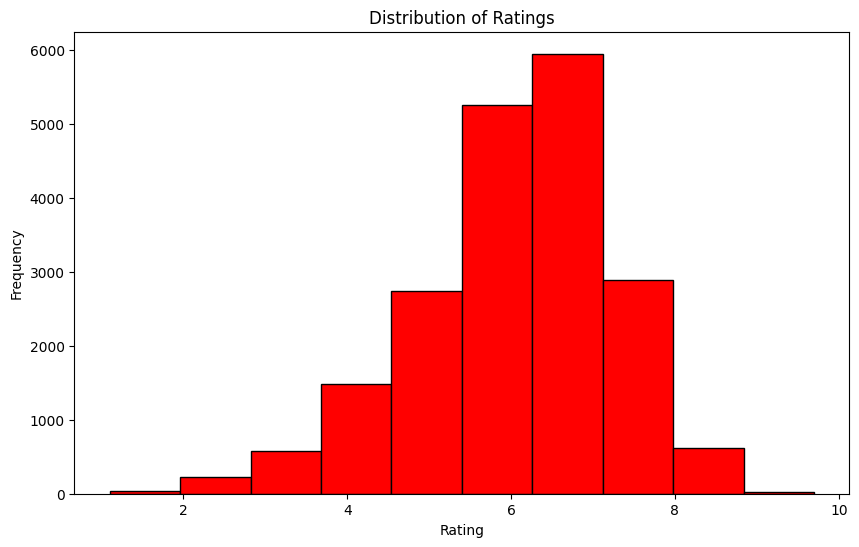

In [ ]:
plt.figure(figsize=(10,6))

plt.hist(df["rating"], bins=10, edgecolor="Black", color="Red")

plt.xlabel("Rating")
plt.ylabel("Frequency")
plt.title("Distribution of Ratings")
plt.show()


### Q4. Rating distribution (Seaborn)

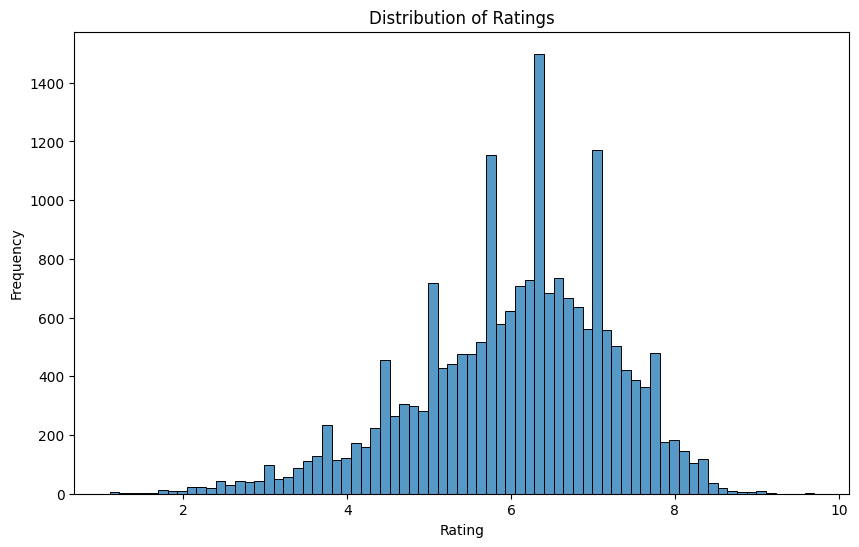

In [ ]:

plt.figure(figsize=(10,6))

sns.histplot(df["rating"])

plt.xlabel("Rating")
plt.ylabel("Frequency")
plt.title("Distribution of Ratings")
plt.show()


### Q5. Top 10 actors

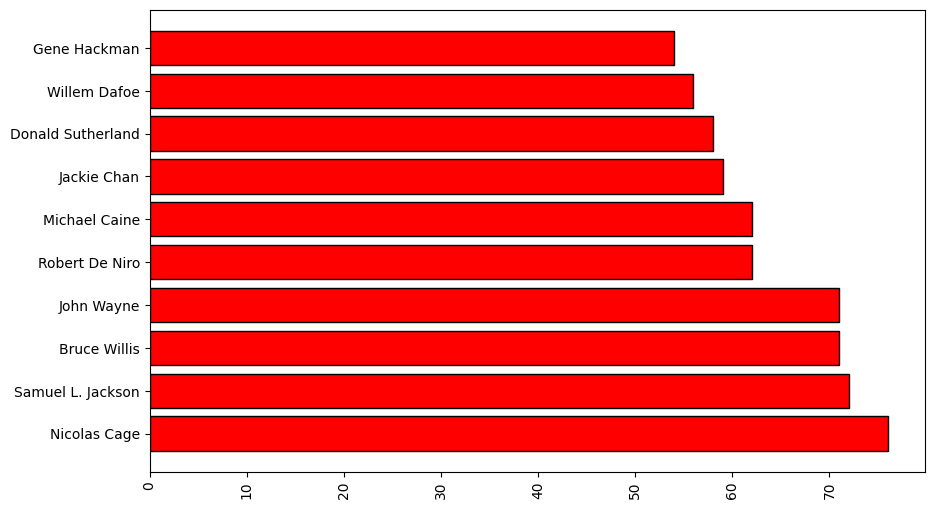

In [ ]:

num_star = df["stars_name"].str.split(",").explode("star_name")

num_star = num_star.value_counts().head(10)

plt.figure(figsize=(10,6))

plt.barh(y = num_star.index , width =num_star.values, color= "red", edgecolor="black")
plt.xticks(rotation=90)
plt.show()

### Q6. Year vs Rating

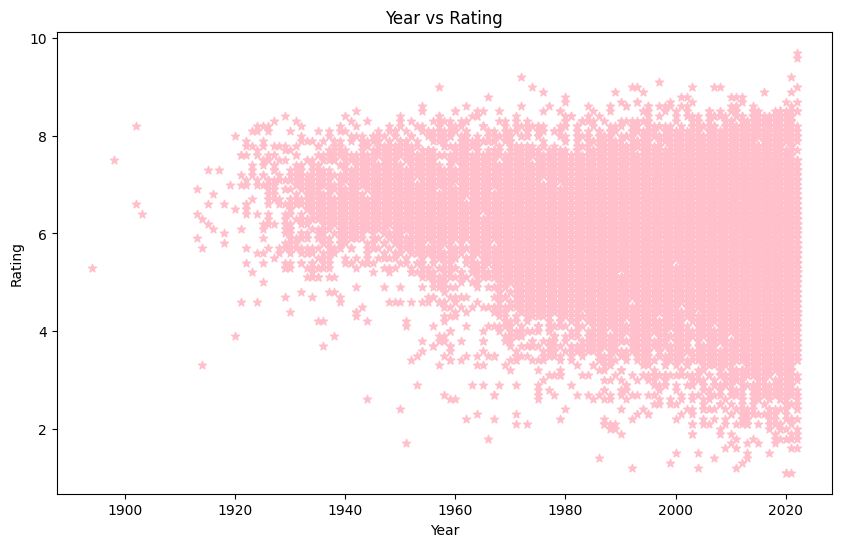

In [ ]:

plt.figure(figsize=(10,6))

plt.scatter(df["year"], df["rating"], color="pink", marker="*")
plt.xlabel("Year")
plt.ylabel("Rating")
plt.title("Year vs Rating")
plt.show()


### Q7. Gross & Votes Distribution

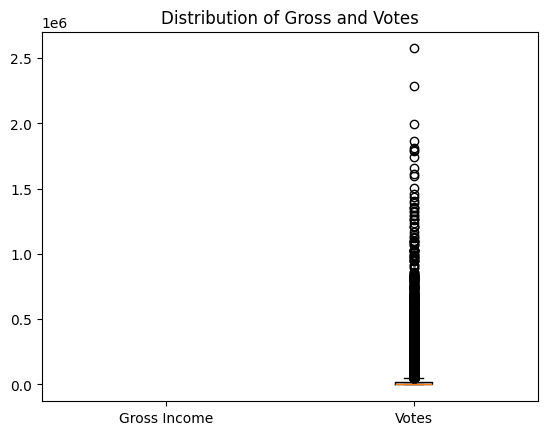

In [174]:

plt.figure()
plt.boxplot([df["gross_income"], df["votes"]])
plt.xticks([1,2],["Gross Income","Votes"])
plt.title("Distribution of Gross and Votes")
plt.show()


### Q8. Count plot for top actors

/tmp/ipykernel_1750/1413042001.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(y=a, order=top10, palette = "viridis")


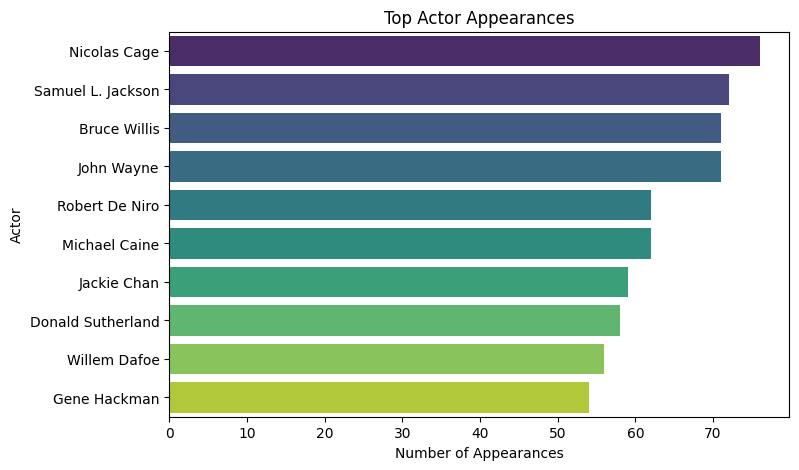

In [169]:
a = df["stars_name"].str.split(",").explode().reset_index(drop=True)

top10 = a.value_counts().head(10).index

plt.figure(figsize=(8,5))

sns.countplot(y=a, order=top10, palette = "viridis")

plt.title("Top Actor Appearances")
plt.xlabel("Number of Appearances")
plt.ylabel("Actor")

plt.show()

### Q9. Correlation heatmap

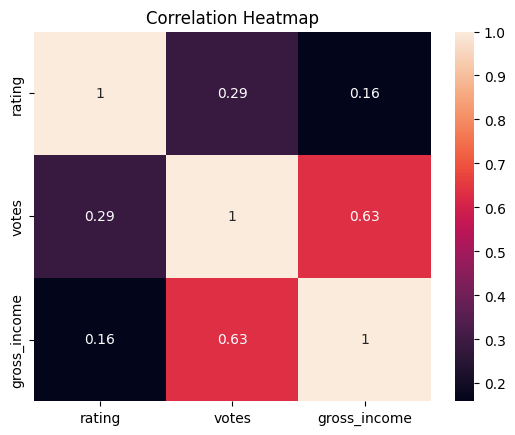

In [175]:

plt.figure()
sns.heatmap(df[["rating","votes","gross_income"]].corr(), annot=True)
plt.title("Correlation Heatmap")
plt.show()


### Q10. Full numeric correlation

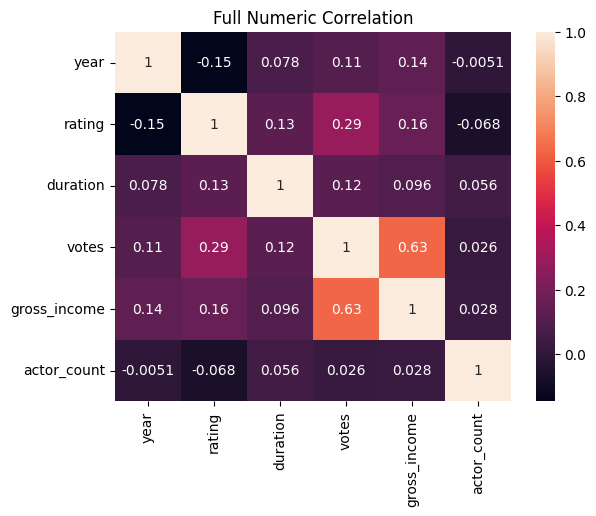

In [176]:

plt.figure()
sns.heatmap(df.select_dtypes(include="number").corr(), annot=True)
plt.title("Full Numeric Correlation")
plt.show()


### Stacked Bar Chart Example

<Figure size 1000x1000 with 0 Axes>

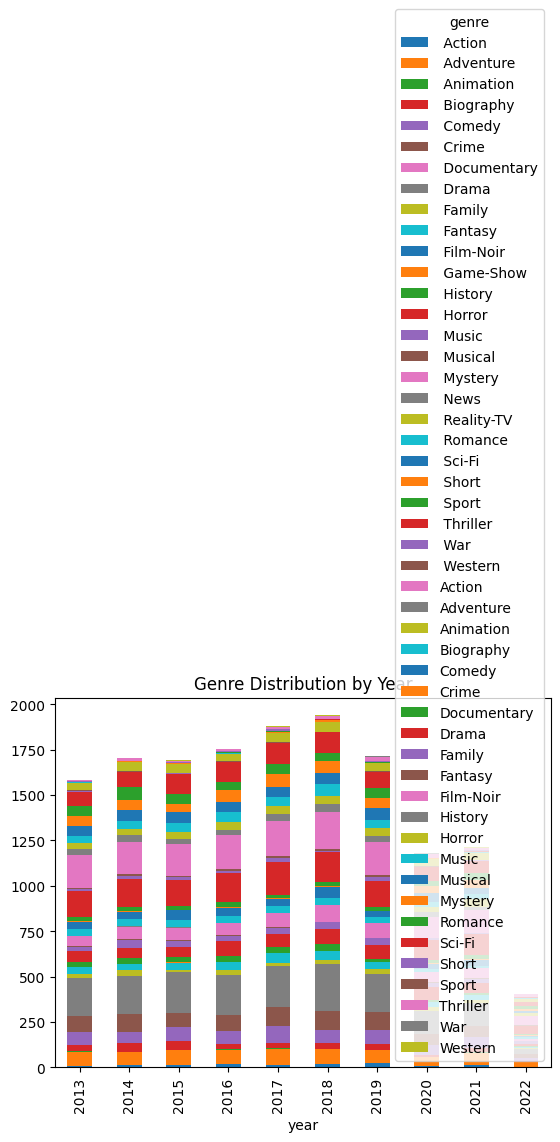

In [179]:
plt.figure(figsize=(10,10))

genre_year = genres.groupby(["year","genre"]).size().unstack().fillna(0)

genre_year.tail(10).plot(kind="bar", stacked=True)
plt.title("Genre Distribution by Year")
plt.show()


### Pie Chart Example

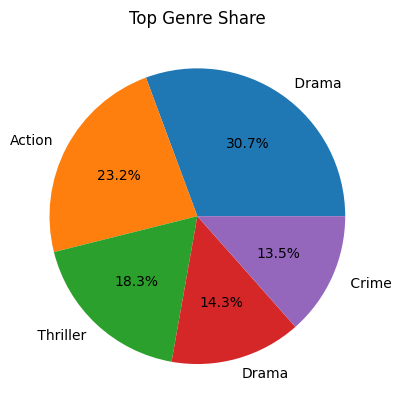

In [180]:

top_genres = genres["genre"].value_counts().head(5)

plt.figure()
plt.pie(top_genres, labels=top_genres.index, autopct="%1.1f%%")
plt.title("Top Genre Share")
plt.show()
